In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import pandas as pd
import seaborn as sns

In [3]:
dlclahe = np.load("dlcnn_MS_CLAHE_conf.npy")
dlnclahe = np.load("dlcnn_MS_NONCLAHE_conf.npy")
dlclaheuns = np.load("dlcnn_MS_CLAHE_unseen_conf.npy")
mcclahe = np.load("multiclass_CLAHE_confidence_Training_values.npy")
mcnclahe = np.load("multiclass_NONCLAHE_training.npy")
mcclaheuns = np.load("multiclass_CLAHE_confidence_values.npy")

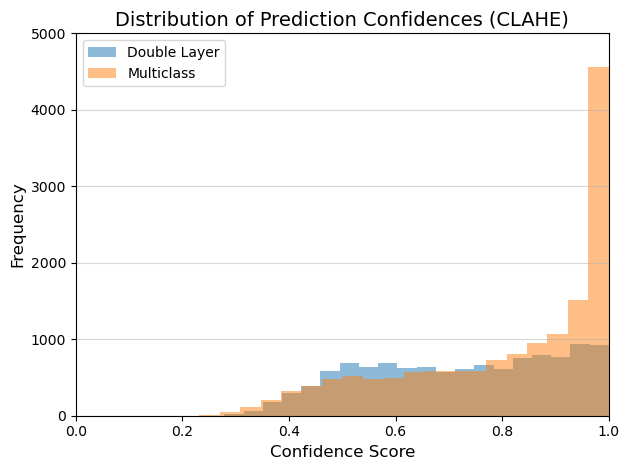

In [4]:
fig, ax = plt.subplots()
    
ax.hist(dlclahe, label="Double Layer", bins=20, alpha=0.5)
ax.hist(mcclahe, label="Multiclass", bins=20, alpha=0.5)

ax.set_title("Distribution of Prediction Confidences (CLAHE)", fontsize=14)
ax.set_xlabel("Confidence Score", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.set_xlim([0, 1.0])
ax.set_ylim([0, 5000])
ax.grid(axis='y', alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()

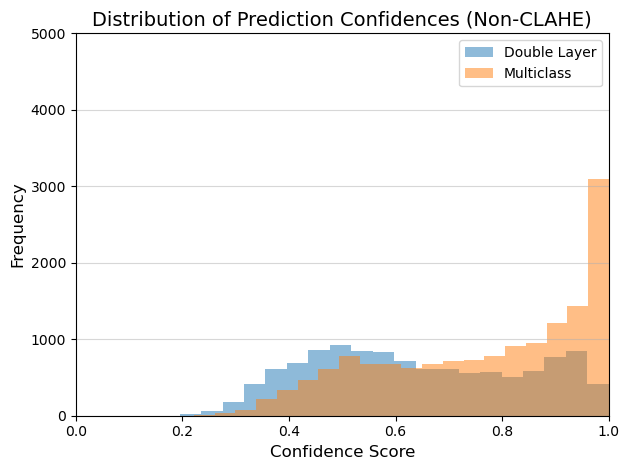

In [5]:
fig, ax = plt.subplots()
    
ax.hist(dlnclahe, label="Double Layer", bins=20, alpha=0.5)
ax.hist(mcnclahe, label="Multiclass", bins=20, alpha=0.5)

ax.set_title("Distribution of Prediction Confidences (Non-CLAHE)", fontsize=14)
ax.set_xlabel("Confidence Score", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.set_xlim([0, 1.0])
ax.set_ylim([0, 5000])
ax.grid(axis='y', alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()

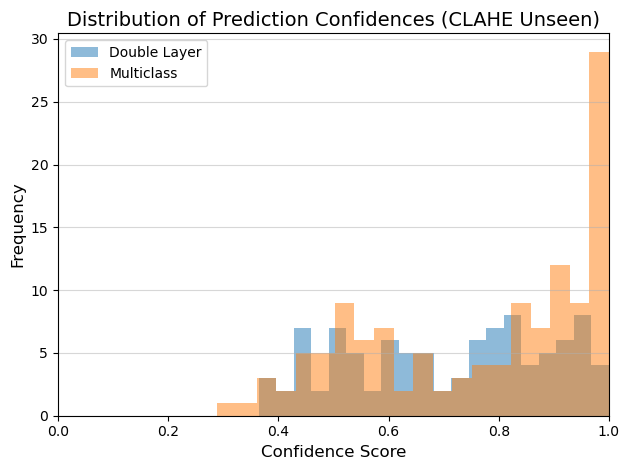

In [6]:
fig, ax = plt.subplots()
    
ax.hist(dlclaheuns, label="Double Layer", bins=20, alpha=0.5)
ax.hist(mcclaheuns, label="Multiclass", bins=20, alpha=0.5)

ax.set_title("Distribution of Prediction Confidences (CLAHE Unseen)", fontsize=14)
ax.set_xlabel("Confidence Score", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.set_xlim([0, 1.0])
ax.grid(axis='y', alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()

In [15]:
dltrue = np.load("dlcnn_MS_CLAHE_ytrue.npy")
dlpred = np.load("dlcnn_MS_CLAHE_ypred.npy")
y_immunetrue = np.concatenate((dltrue, np.ones(round(0.9144*3000))*4))
y_immunepred = np.concatenate((dlpred, np.ones(round(0.9144*3000))*4))
labels = ["Invasive", "DCIS 1", "DCIS 2", "Prolif Invasive", "Immune"]

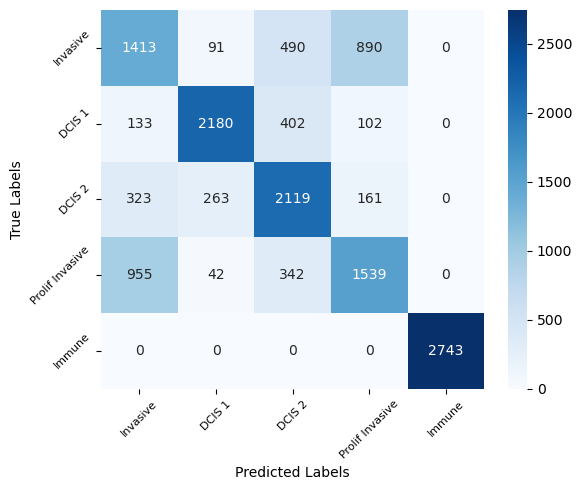

In [20]:
cm = confusion_matrix(y_immunetrue, y_immunepred, labels=range(len(labels)))
df_cm = pd.DataFrame(cm, index=labels, columns=labels)
    
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(df_cm, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_xlabel('Predicted Labels')
ax.set_ylabel('True Labels')
    
plt.xticks(rotation=45, fontsize=8)
plt.yticks(rotation=45, fontsize=8)
plt.tight_layout()

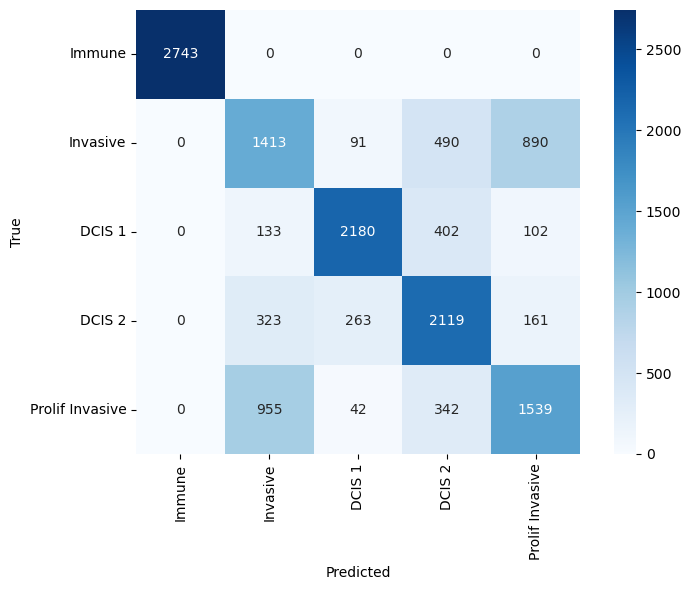

In [34]:
dltrue = np.load("dlcnn_MS_CLAHE_ytrue.npy") + 1
dlpred = np.load("dlcnn_MS_CLAHE_ypred.npy") + 1
y_immunetrue = np.concatenate((dltrue, np.zeros(round(0.9144*3000))))
y_immunepred = np.concatenate((dlpred, np.zeros(round(0.9144*3000))))
labels = ["Immune", "Invasive", "DCIS 1", "DCIS 2", "Prolif Invasive"]

cm = confusion_matrix(y_immunetrue, y_immunepred, labels=range(len(labels)))
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, square=True)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("dlcnn_clahe_cm.png", dpi=300)
plt.show()

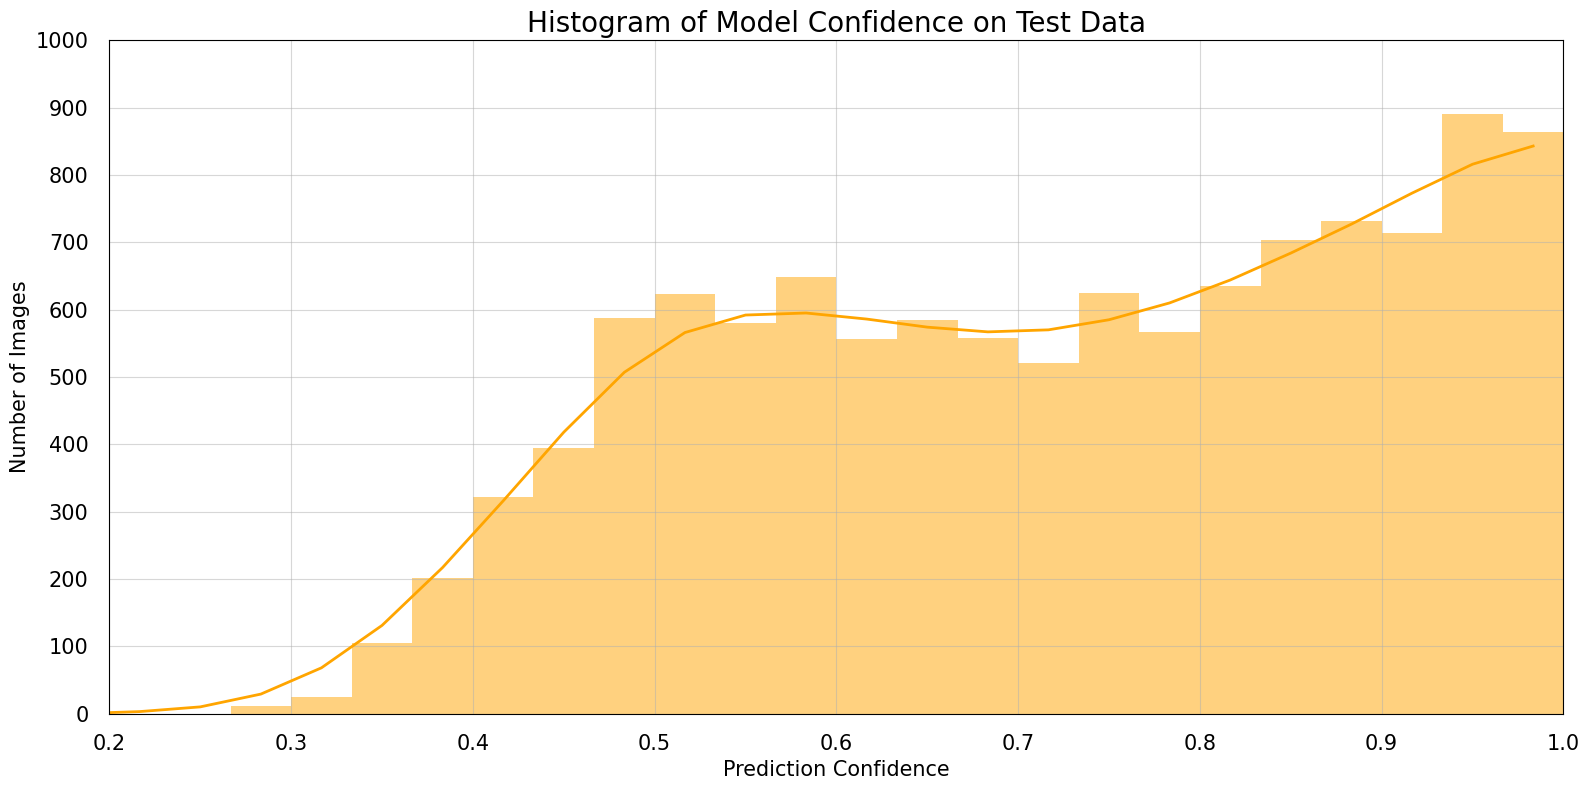

In [77]:
from scipy.ndimage import gaussian_filter1d
import matplotlib.ticker as ticker

dlclahe = np.array(dlclahe).astype(float)
counts, bin_edges = np.histogram(dlclahe, bins=30, range=(0,1))
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

smoothed_counts = gaussian_filter1d(counts, sigma=1.5)

fig, ax = plt.subplots(figsize=(16, 8))

ax.hist(dlclahe, bins=30, range=(0,1), color="orange", alpha=0.5, histtype='stepfilled')

ax.plot(bin_centers, smoothed_counts, color='orange', linewidth=2)

ax.set_title("Histogram of Model Confidence on Test Data", fontsize=20)
ax.set_xlabel("Prediction Confidence", fontsize=15)
ax.set_ylabel("Number of Images", fontsize=15)
ax.tick_params(axis='both', which='both', length=0)
ax.tick_params(axis='x', pad=15)
ax.tick_params(axis='y', pad=15)
plt.xlim([0.2, 1])
plt.ylim(0, 1000)
plt.gca().yaxis.set_major_locator(ticker.MultipleLocator(100))
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
ax.grid(alpha=0.5)

plt.tight_layout()
plt.savefig("dlcnn_confplot.png", dpi=300)
plt.show()

In [ ]:
fig, ax = plt.subplots()
    
ax.hist(dlnclahe, label="Double Layer", bins=20, alpha=0.5)
ax.hist(mcnclahe, label="Multiclass", bins=20, alpha=0.5)

ax.set_title("Distribution of Prediction Confidences (Non-CLAHE)", fontsize=14)
ax.set_xlabel("Confidence Score", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.set_xlim([0, 1.0])
ax.set_ylim([0, 5000])
ax.grid(axis='y', alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()